# Taller: Escuchar al cliente con datos
## Análisis de sentimientos + clustering para decisiones de negocio
### Caso **Ceiba Pay** — billetera digital

**Pregunta de negocio:** *¿Qué segmentos de clientes tiene Ceiba Pay, qué siente cada uno sobre el servicio y dónde debe concentrar la compañía su presupuesto 2027 para proteger el margen y crecer?*


## ¿De qué se quejan y qué valoran? Temas

El sentimiento dice *cómo se siente* el cliente; pero es importante conocer los temas los cuales se quejan para poder actuar. Para que la compañía pueda actuar (el mismo trabajo que haría un analista en la vida real).

## Segmentación de clientes con K-means

Segmentación de clientes teniendo en cuenta el uso de la billetera (cómo usan la billetera), sin tener en cuenta el sentimiento. Así, en el Bloque 5, podemos preguntar algo útil: *¿cada grupo de comportamiento siente distinto?*

**Recomendaciones de preparación de los datos**
* Montos y conteos (transacciones, ticket, saldo, días) están muy sesgados, se recomienda hacer transformación logarítmica.
* Las variables están en escalas distintas (pesos vs. porcentajes), es muy importante hacer estandarización.
* Edad, estrato y ciudad, no se deben usar en el clustering, se utilizan en la caracterización de los segmentos.

## Informe final de recomendaciones
Se deben preparar 3 recomendacionaciones para el presupuesto 2027 con esta estructura:

- Hallazgo
- Segmento
- Acción concreta
- Indicador de seguimiento

# 0 - Setup

In [64]:
# Install packages not preinstalled in Colab (Marian translator needs sentencepiece + sacremoses)
!pip install -q textblob sentencepiece sacremoses

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 0.2 - Imports

In [65]:
# ---- Global imports: everything the notebook uses lives here
import re, hashlib, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import TweetTokenizer
from wordcloud import WordCloud
from textblob import TextBlob
from transformers import MarianMTModel, MarianTokenizer  # ES -> EN translation for TextBlob

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             f1_score, confusion_matrix)
import joblib
import torch

for pkg in ["stopwords", "punkt"]:
    nltk.download(pkg, quiet=True)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
print("Imports OK") # Checkpoint

Imports OK


## 0.3 - Configuration

In [66]:
# ---- Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---- Paths (raw file is never modified; outputs go to separate folders)
PROJECT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/No supervisado/Workshops/Workshop 5 - Ceiba Pay Clients")
DATA_FILE   = PROJECT_DIR / "data" / "ceiba_pay_clientes.xlsx"
FIG_DIR     = PROJECT_DIR / "reports" / "figures"
OUT_DIR     = PROJECT_DIR / "outputs"
MODEL_DIR   = PROJECT_DIR / "models"
for d in [FIG_DIR, OUT_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ---- Colorblind-safe palettes; each encoding has its own colors (never reused)
SENTIMENT_COLORS = {"Negativo": "#D55E00", "Neutro": "#9E9E9E", "Positivo": "#0072B2"}
SEGMENT_PALETTE  = ["#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#882255", "#44AA99"]
SEQ_CMAP = "Blues"    # ordinal / sequential
DIV_CMAP = "RdBu_r"   # z-scores, diverging around 0

sns.set_theme(style="whitegrid", rc={
    "axes.titlelocation": "left", "axes.titlesize": 13,
    "axes.titleweight": "bold", "grid.alpha": 0.3, "figure.dpi": 110})

def save_fig(fig, name, module):
    """Save a figure as PNG with a module prefix."""
    path = FIG_DIR / f"{module:02d}_{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    return path

def cop_fmt(x, _=None):
    """Format COP amounts as $150k / $1.2M for axes and tables."""
    return f"${x/1e6:.1f}M" if abs(x) >= 1e6 else f"${x/1e3:.0f}k"

print("Data file exists:", DATA_FILE.exists())

Data file exists: True


## 0.4 - Original file fingerprint

In [67]:
def file_md5(path):
    """Return the MD5 hash of a file to prove it was never modified."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

MD5_ORIGINAL = file_md5(DATA_FILE)
print("MD5 original:", MD5_ORIGINAL)

MD5 original: 3fcea7708df095a7677b249cdc8723b9


# 1 - Data Loading and Diagnostics

In [68]:
# Raw data stays untouched in df_raw; all work happens on df
df_raw = pd.read_excel(DATA_FILE)
df_raw.columns = (df_raw.columns.str.strip().str.lower()
                  .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
df = df_raw.copy()

print("Shape:", df.shape)
df.head(3).T
# We obtain a 2000 rows dataset with 21 columns of variables for each client (Assuming there are no repeated clients)

Shape: (2000, 21)


,0,1,2
id_cliente,CP100000,CP100001,CP100002
edad,19.0,24.0,45.0
estrato,1,3,1
ciudad,Bogotá,Municipio intermedio,Bucaramanga
canal_adquisicion,Referido,Pauta digital,Pauta digital
antiguedad_meses,9,7,3
transacciones_mes,28,26,2
ticket_promedio_cop,20400,78400,9700
saldo_promedio_cop,44600,1398500,21500
pct_pagos_qr,64.0,226.0,223.0


## 1.2 - Quality Diagnosis

In [69]:
def diagnose(data):
    """One-row-per-column quality summary: type, nulls, cardinality, range.""" # Docstring with a 1 line summary of what the function does. Python shows it with 'help (diagnose)'
    return pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "nulls": data.isna().sum(),
        "pct_nulls": (data.isna().mean() * 100).round(2),
        "uniques": data.nunique(),
        "min": data.min(numeric_only=True),
        "max": data.max(numeric_only=True),
    }).reindex(data.columns)  # keep original column order

diag = diagnose(df)
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate IDs:", df["id_cliente"].duplicated().sum())
diag
# We run a diagnosis on all of the rows per column to have an overlook on the quality of data we have
# We see no duplicates on the printed commentaries above the DataFrame. However, there are indeed 15 null values in the 'edad' variable, and 10 in 'comentario'

Duplicate Rows: 0
Duplicate IDs: 0


,dtype,nulls,pct_nulls,uniques,min,max
id_cliente,object,0,0.00,2000,NaN,NaN
edad,float64,15,0.75,63,18.00,80.0
estrato,int64,0,0.00,6,1.00,6.0
ciudad,object,0,0.00,8,NaN,NaN
canal_adquisicion,object,0,0.00,4,NaN,NaN
antiguedad_meses,int64,0,0.00,58,1.00,60.0
transacciones_mes,int64,0,0.00,251,0.00,510.0
ticket_promedio_cop,int64,0,0.00,1159,5300.00,1116400.0
saldo_promedio_cop,int64,0,0.00,1675,700.00,13294500.0
pct_pagos_qr,float64,0,0.00,577,0.00,896.0


## 1.3 - Percentage Scale
As noted on the dataset obtained above, there are four columns (On the obtained output case: rows) which starts by 'pct'. This refers to a percentage of, for example 'P2P Transactions'.

We must scale these:

In [70]:
# The 4 channel shares should add up to 100% per customer
PCT_COLS = [c for c in df.columns if c.startswith("pct_")]
row_sum = df[PCT_COLS].sum(axis=1)
frac_cells = ((df[PCT_COLS] > 0) & (df[PCT_COLS] < 1)).sum()

print("Suma por fila de pct_*:")
print(row_sum.describe().round(1))
print("\nCeldas entre 0 y 1 (escala fracción):")
print(frac_cells)
df.loc[[0, 3, 9], PCT_COLS].assign(suma=row_sum)

Suma por fila de pct_*:
count    2000.0
mean      900.2
std       212.3
min         1.0
25%       920.8
50%      1000.0
75%      1000.0
max      1001.0
dtype: float64

Celdas entre 0 y 1 (escala fracción):
pct_pagos_qr                165
pct_transferencias_p2p      198
pct_retiros_corresponsal    170
pct_pago_servicios          203
dtype: int64


,pct_pagos_qr,pct_transferencias_p2p,pct_retiros_corresponsal,pct_pago_servicios,suma
0,64.0,789.0,51.0,95.00,999.00
3,13.0,289.0,588.0,0.11,890.11
9,0.1,699.0,64.0,136.00,899.10


- The four usage percentages by channel (pct_*) are expressed per thousand: each customer adds 1,000 instead of 100.
- In addition, 736 cells for 637 customers are written as fractions (0.11 = 11%), which is why some totals come out to 1.
- This is corrected using a verifiable rule: the fractions are multiplied by 1,000, everything is divided by 10, and it is verified that each row totals 100%. No customers are removed.

# 2 - Data Cleaning + Audit Log

In [71]:
# Audit log: every cleaning decision is recorded here
# Re-run from 1 if needed: cleaning steps are not idempotent (e.g. ÷10 twice breaks pct_*)
# “Idempotent” means that running it once or multiple times gives the same result. The cells in Module 2 are not idempotent
cleaning_log = []

def log_step (step, issue, rows, decision, reason):
    """Append one cleaning decision to the audit log."""
    cleaning_log.append({"step" : step, "issue" : issue, "affected_rows" : int(rows),
    "decision" : decision, "justification" : reason})
    print(f"[{step}] {issue} -> {rows} rows affected")

## 2.2 - Percentage Scale

In [72]:
# Cells between 0 and 1 are fractions (0.11 = 11%) -> convert to per-mille first
frac_mask = (df[PCT_COLS] > 0) & (df[PCT_COLS] < 1)
n_frac_rows = frac_mask.any(axis=1).sum()

df[PCT_COLS] = df[PCT_COLS].mask(frac_mask, df[PCT_COLS] * 1000)
df[PCT_COLS] = df[PCT_COLS] / 10   # per-mille -> percent

log_step("2.2", "pct_* stored in per-mille (×10) + 736 cells as fractions", n_frac_rows,
         "Fractions ×1000, then all ÷10", "Each row must add up to 100%; verifiable rule")

check = df[PCT_COLS].sum(axis=1)
print("Row sum after fix:", round(float(check.min()), 2), "-", round(float(check.max()), 2))

[2.2] pct_* stored in per-mille (×10) + 736 cells as fractions -> 637 rows affected
Row sum after fix: 99.9 - 100.1


## 2.3 - Missing Age

In [73]:
# Impute missing ages with the median (Age is only used for profiling, not clustering)
n_age_null = df["edad"].isna().sum() # Counts the null values on "edad" column and sums them
AGE_MEDIAN = df["edad"].median()

df["flag_age_imputed"] = df["edad"].isna().astype(int)
df["edad"] = df["edad"].fillna(AGE_MEDIAN)

log_step("2.3", "Missing ages", n_age_null, f"Median imputation ({AGE_MEDIAN:.0f}) + flag", # flag = leaving a memo indicating these values had an issue
         "0.75% of rows; age is only used for profiling, not for clustering")

[2.3] Missing ages -> 15 rows affected


## 2.4 - Missing Comments

In [74]:
# Keep these customers for clusteringg but exclude them only from NLP
df["flag_no_comment"] = df["comentario"].isna().astype(int)

log_step("2.4", "Missing comments", df["flag_no_comment"].sum(), "Keep + flag",
         "Customer still counts for clustering model; excluded from NLP only")

[2.4] Missing comments -> 10 rows affected


## 2.5 - Logic Rules

In [75]:
# Rule 1: Nobody can be inactive longer than they have been a customer (+30 days tolerance because tenure is rounded to whole months)
max_days = df["antiguedad_meses"] * 30
bad_days = df["dias_desde_ultima_tx"] > max_days + 30
df["flag_days_capped"] = bad_days.astype(int)
df.loc[bad_days, "dias_desde_ultima_tx"] = max_days[bad_days]

log_step("2.5a", "Days since last tx > account tenure", bad_days.sum(),
         "Cap at tenure x 30 + flag", "Nobody can be inactive longer than they have been a customer")

# Rule 2: Zero transactions this month -> real inactive users, not errors
df["flag_inactive"] = (df["transacciones_mes"] == 0).astype(int)

log_step("2.5b", "Customers with 0 transactions this month", df["flag_inactive"].sum(),
         "Keep + flag", "Real users (>= 34 days without tx); churn-risk group")

[2.5a] Days since last tx > account tenure -> 45 rows affected
[2.5b] Customers with 0 transactions this month -> 24 rows affected


## 2.6 - Export + chart

In [76]:
log_df = pd.DataFrame(cleaning_log)
log_df.to_excel(OUT_DIR / "02_cleaning_log.xlsx", index=False)
df.to_excel(OUT_DIR / "02_ceiba_pay_clean.xlsx", index=False)
print("Remaining nulls:", df.isna().sum()[lambda s : s > 0].to_dict())

Remaining nulls: {'comentario': 10}


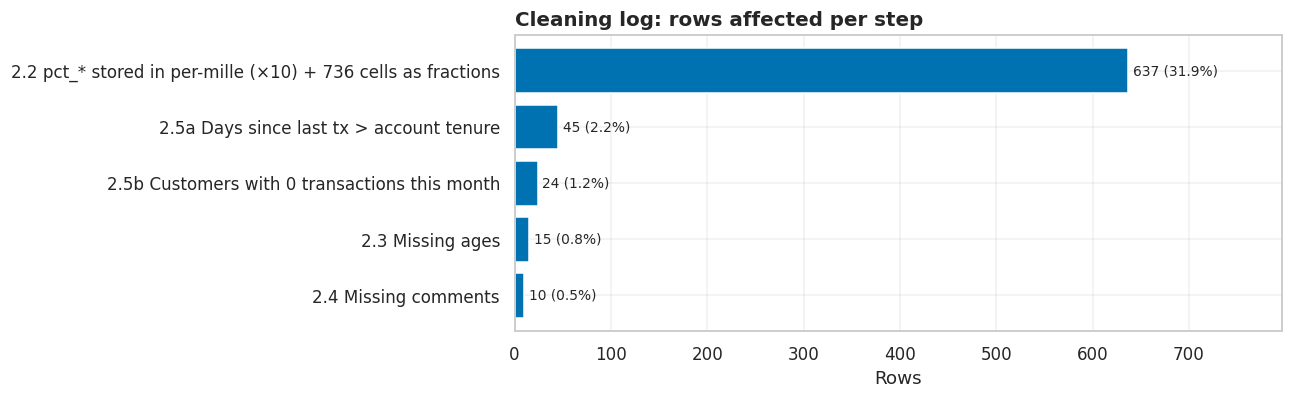

,step,issue,affected_rows,decision,justification
0,2.2,pct_* stored in per-mille (×10) + 736 cells as fractions,637,"Fractions ×1000, then all ÷10",Each row must add up to 100%; verifiable rule
1,2.3,Missing ages,15,Median imputation (32) + flag,"0.75% of rows; age is only used for profiling, not for clustering"
2,2.4,Missing comments,10,Keep + flag,Customer still counts for clustering model; excluded from NLP only
3,2.5a,Days since last tx > account tenure,45,Cap at tenure x 30 + flag,Nobody can be inactive longer than they have been a customer
4,2.5b,Customers with 0 transactions this month,24,Keep + flag,Real users (>= 34 days without tx); churn-risk group


In [77]:
# Visual summary of the audit log
plot_df = log_df.sort_values("affected_rows")
fig, ax = plt.subplots(figsize = (9 , 3.5))
ax.barh(plot_df["step"] + " " + plot_df["issue"], plot_df["affected_rows"], color = "#0072B2")

for i, v, in enumerate (plot_df["affected_rows"]):
  ax.text(v + 5, i, f"{v} ({v/len(df):.1%})", va="center", fontsize=9)

ax.set_title("Cleaning log: rows affected per step")
ax.set_xlabel("Rows")
ax.set_xlim(0, plot_df["affected_rows"].max() * 1.25)
save_fig(fig, "cleaning_log", module =2)
plt.show()

log_df

# 3 - Outliers
Count outliers using IQR and Z-Score on the original scale

In [78]:
# Counting on the original scale
# Numeric columns to audit; the first 5 are heavily skewed money/count variables

SKEWED_COLS = ["transacciones_mes", "ticket_promedio_cop", "saldo_promedio_cop", "dias_desde_ultima_tx", "margen_mensual_cop"] # Most of these are currency-related or count-related.
OUTLIER_COLS = SKEWED_COLS + ["antiguedad_meses", "contactos_soporte_6m", "edad"]

def iqr_outliers(s):
    """Boolean mask of values outside 1.5 x IQR"""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

def z_outliers (s, limit = 3):
    """Boolean mask of balues with |z| > limit"""
    return ((s - s.mean()) / s.std()).abs() > limit

outlier_summary = pd.DataFrame({
    "skew" : df[OUTLIER_COLS].skew().round(2),
    "iqr_raw" : [iqr_outliers(df[c]).sum() for c in OUTLIER_COLS],
    "z_raw" : [z_outliers(df[c]).sum() for c in OUTLIER_COLS],
})
outlier_summary

,skew,iqr_raw,z_raw
transacciones_mes,2.56,279,49
ticket_promedio_cop,2.27,126,42
saldo_promedio_cop,4.14,170,42
dias_desde_ultima_tx,2.65,258,48
margen_mensual_cop,2.70,217,47
antiguedad_meses,0.54,19,8
contactos_soporte_6m,1.23,13,37
edad,0.77,9,9


## 3.2 - Boxplots: original vs log

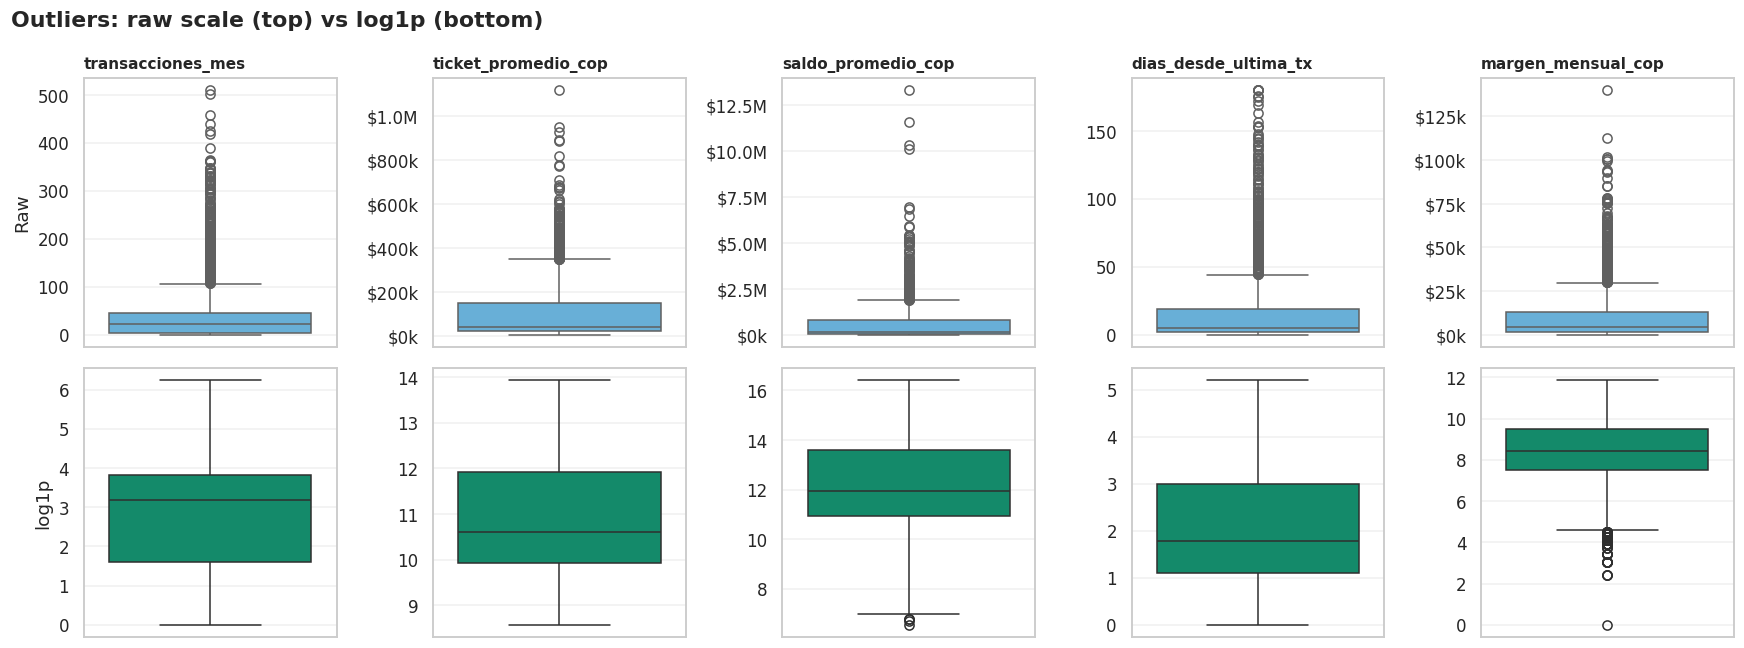

In [79]:
# Log transform only the skewed columns (log1p handles zeros: log(1+0)=0)
log_skewed = np.log1p(df[SKEWED_COLS])

fig, axes = plt.subplots(2, len(SKEWED_COLS), figsize=(16, 6))
for i, col in enumerate(SKEWED_COLS):
    sns.boxplot(y=df[col], ax=axes[0, i], color="#56B4E9")
    sns.boxplot(y=log_skewed[col], ax=axes[1, i], color="#009E73")
    axes[0, i].set_title(col, fontsize=10)
    axes[0, i].set_ylabel("Raw" if i == 0 else "")
    axes[1, i].set_ylabel("log1p" if i == 0 else "")
    if col.endswith("_cop"):
        axes[0, i].yaxis.set_major_formatter(mtick.FuncFormatter(cop_fmt))

fig.suptitle("Outliers: raw scale (top) vs log1p (bottom)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "boxplots_raw_vs_log", module=3)
plt.show()

## 3.3 - Count after "log"

In [80]:
outlier_summary.loc[SKEWED_COLS, "skew_log"] = log_skewed.skew().round(2)
outlier_summary.loc[SKEWED_COLS, "iqr_log"] = [iqr_outliers(log_skewed[c]).sum() for c in SKEWED_COLS]
outlier_summary

,skew,iqr_raw,z_raw,skew_log,iqr_log
transacciones_mes,2.56,279,49,0.01,0.0
ticket_promedio_cop,2.27,126,42,0.36,0.0
saldo_promedio_cop,4.14,170,42,-0.25,4.0
dias_desde_ultima_tx,2.65,258,48,0.40,0.0
margen_mensual_cop,2.70,217,47,-0.75,76.0
antiguedad_meses,0.54,19,8,NaN,NaN
contactos_soporte_6m,1.23,13,37,NaN,NaN
edad,0.77,9,9,NaN,NaN


## 3.4 - flag + Cleaning Log

In [81]:
# Flag only on usage variables that will feed K-Means (margin is an outcome, not an input)
USAGE_SKEWED = ["transacciones_mes", "ticket_promedio_cop", "saldo_promedio_cop", "dias_desde_ultima_tx"]
df["flag_outlier"] = np.log1p(df[USAGE_SKEWED]).apply(iqr_outliers).any(axis=1).astype(int)

log_step("3.4", "IQR outliers in usage vars after log1p", df["flag_outlier"].sum(),
         "Keep + flag", "Raw 'outliers' were skewness; after log1p only extreme low balances remain")

[3.4] IQR outliers in usage vars after log1p -> 4 rows affected


## 3.5 - **Findings – Outliers**
- 1. On the raw scale, IQR flags 126–279 customers per variable (skew 2.3–4.1). This is skewness, not errors: a few heavy users, many light users.
- 2. After `log1p`, skew drops to |0.4| or less and outliers almost disappear (4 customers with very low balances). → `log1p` is applied before clustering, as the brief recommends.
- 3. No customers are removed: extreme values are real behavior and the most valuable or riskiest customers.
- 4. `margen_mensual_cop` keeps 76 low-end outliers (≤ $90 COP/month): near-inactive users (≤ 3 tx/month). It is not a clustering input; it will be used to profile segments.

# 4 - EDA (Exploratory Data Analysis)

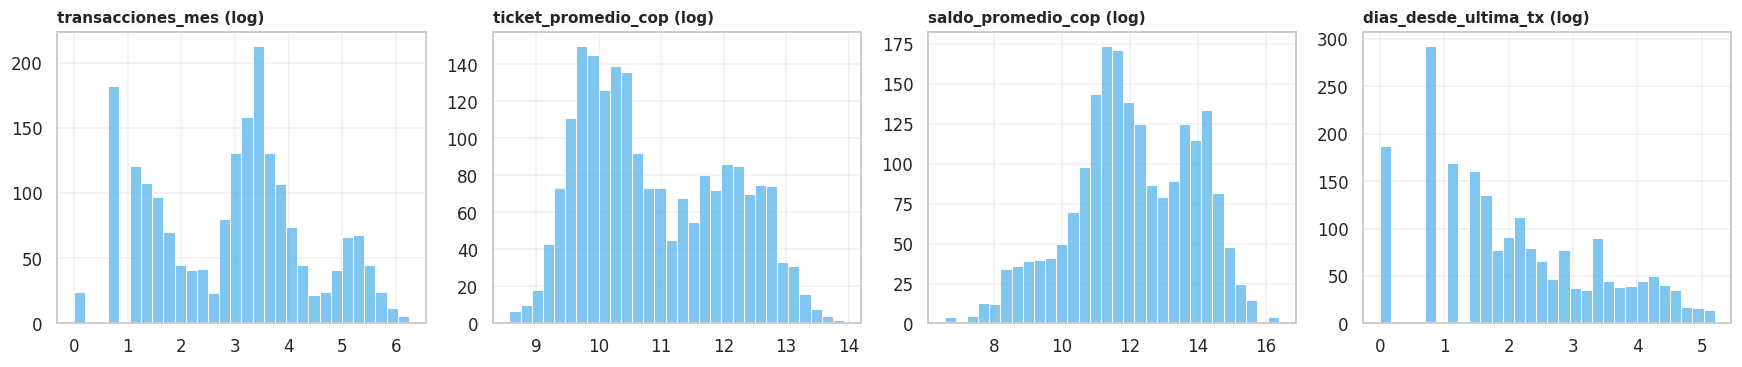

Median share of each transaction type (%):
pct_pagos_qr                14.6
pct_transferencias_p2p      33.9
pct_retiros_corresponsal     9.3
pct_pago_servicios          12.3
dtype: float64


In [82]:
# WALLET USAGE:
# Log scale because these variables are highly skewed (see Module 3)
USAGE_COLS = ["transacciones_mes", "ticket_promedio_cop", "saldo_promedio_cop", "dias_desde_ultima_tx"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, USAGE_COLS):
    sns.histplot(np.log1p(df[col]), bins=30, ax=ax, color="#56B4E9")
    ax.set_title(col + " (log)", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.tight_layout()
save_fig(fig, "usage_distributions", module=4)
plt.show()

print("Median share of each transaction type (%):")
print(df[PCT_COLS].median().round(1))

## 4.2 - Customer Profile

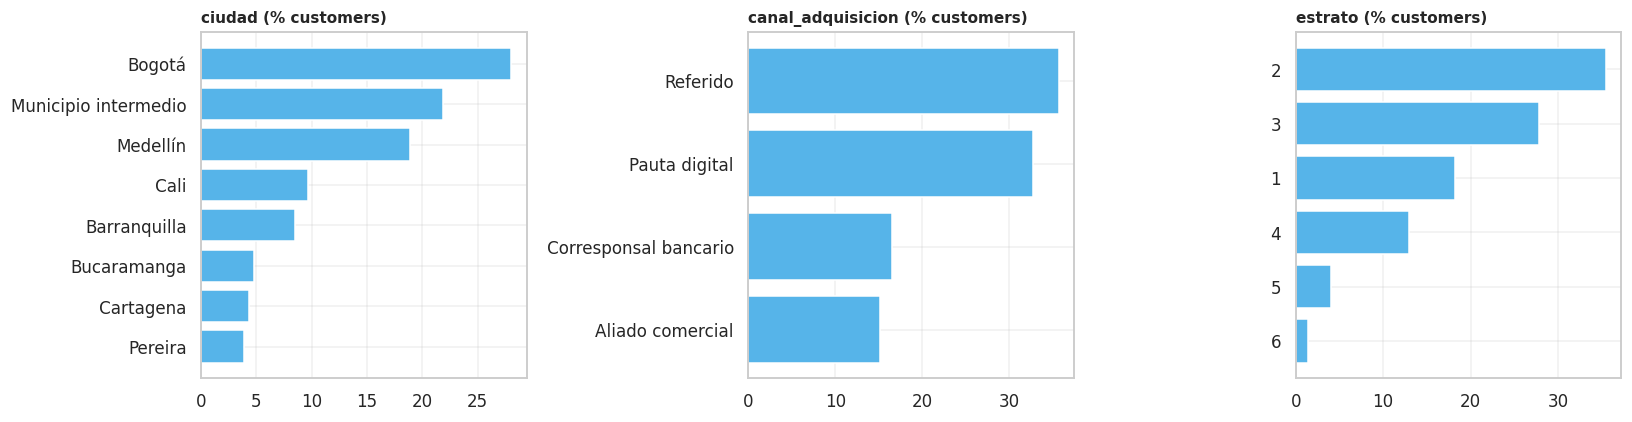

In [83]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["ciudad", "canal_adquisicion", "estrato"]):
    share = df[col].value_counts(normalize=True).sort_values() * 100
    ax.barh(share.index.astype(str), share.values, color="#56B4E9")
    ax.set_title(f"{col} (% customers)", fontsize=10)
fig.tight_layout()
save_fig(fig, "customer_profile", module=4)
plt.show()

## 4.3 - Net Promoter Score (NPS)

nps_group
Detractor    43.0
Passive      21.8
Promoter     35.2
Name: proportion, dtype: float64
NPS = -8


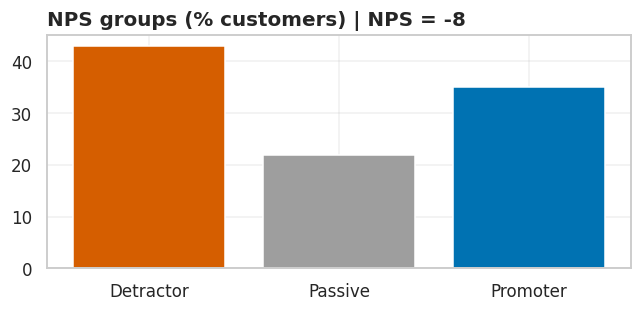

In [84]:
# Standard NPS groups: 0-6 detractor, 7-8 passive, 9-10 promoter
df["nps_group"] = pd.cut(df["nps_0_10"], bins=[-1, 6, 8, 10],
                         labels=["Detractor", "Passive", "Promoter"])
nps_share = df["nps_group"].value_counts(normalize=True, sort=False) * 100
NPS_SCORE = nps_share["Promoter"] - nps_share["Detractor"]
print(nps_share.round(1))
print(f"NPS = {NPS_SCORE:.0f}")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(nps_share.index, nps_share.values, color=list(SENTIMENT_COLORS.values()))
ax.set_title(f"NPS groups (% customers) | NPS = {NPS_SCORE:.0f}")
fig.tight_layout()
save_fig(fig, "nps_groups", module=4)
plt.show()

## 4.4 - Correlations

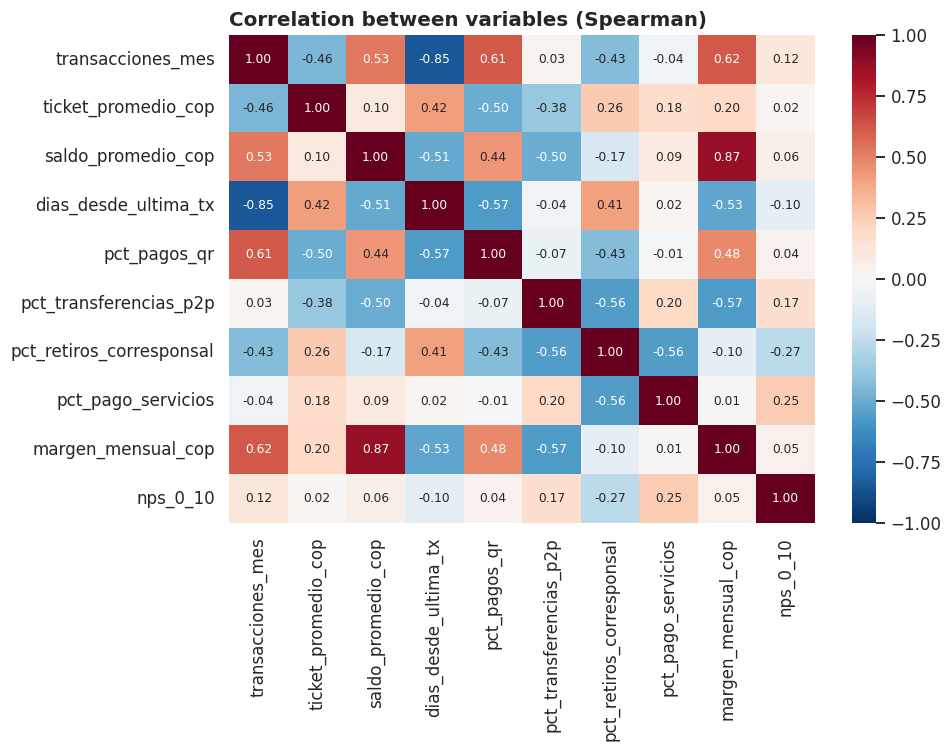

,nps_0_10,margen_mensual_cop
transacciones_mes,0.12,0.62
ticket_promedio_cop,0.02,0.20
saldo_promedio_cop,0.06,0.87
dias_desde_ultima_tx,-0.10,-0.53
pct_pagos_qr,0.04,0.48
pct_transferencias_p2p,0.17,-0.57
pct_retiros_corresponsal,-0.27,-0.10
pct_pago_servicios,0.25,0.01
margen_mensual_cop,0.05,1.00
nps_0_10,1.00,0.05


In [85]:
# Spearman: like normal correlation but robust to skewed data
CORR_COLS = USAGE_COLS + PCT_COLS + ["margen_mensual_cop", "nps_0_10"]
corr = df[CORR_COLS].corr(method="spearman").round(2)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap=DIV_CMAP, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation between variables (Spearman)")
fig.tight_layout()
save_fig(fig, "correlation", module=4)
plt.show()

corr[["nps_0_10", "margen_mensual_cop"]]

## 4.5 - **Findings – EDA**
- 1. **NPS = −8**: more detractors (43%) than promoters (35%).
- 2. **Cash withdrawals hurt satisfaction**: customers who withdraw more cash at corresponsales give lower scores (ρ = −0.27).
- 3. **Margin comes from balance and activity** (ρ = 0.87 and 0.62); P2P-heavy users generate little margin.
- 4. **Two peaks** in transactions and ticket suggest distinct usage groups, useful for K-Means.
- 5. **QR code payments** is a strong indicator on amount of transactions per month (ρ = 0.61)

# 5 - Text Cleaning

In [86]:
def clean_text(text):
    """Lowercase and keep only Spanish letters and spaces"""
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text) # URLs
    text = re.sub(r"@\w+|#", " ", text) # Mentions and hashtags
    text = re.sub(r"[^a-záéíóúüñ\s]", " ", text) # Emojis, numbers, punctuations
    return re.sub(r"\s+", " ", text).strip() # Extra spaces

df["comment_clean"] = df["comentario"].fillna(" ").apply(clean_text) # We input (" ") in all 10 cases of empty comments and then apply the function we created to clean up the text.
df.loc[[0, 3, 7]], ["comentario", "comment_clean"] # Print some random cases to see the differences

(  id_cliente  edad  estrato                ciudad canal_adquisicion  \
 0   CP100000  19.0        1                Bogotá          Referido   
 3   CP100003  53.0        1  Municipio intermedio          Referido   
 7   CP100007  23.0        2                  Cali     Pauta digital   
 
    antiguedad_meses  transacciones_mes  ticket_promedio_cop  \
 0                 9                 28                20400   
 3                36                  2               337300   
 7                17                 34                38800   
 
    saldo_promedio_cop  pct_pagos_qr  pct_transferencias_p2p  \
 0               44600           6.4                    78.9   
 3              227200           1.3                    28.9   
 7               72400          10.7                    82.2   
 
    pct_retiros_corresponsal  pct_pago_servicios  usa_bolsillo_ahorro  \
 0                       5.1                 9.5                    0   
 3                      58.8                11.0

## 5.2 - Tokens + Top Words

In [87]:
# Keep negations: "no" changes the meaning ("no la recomiendo")
STOP_ES = set(stopwords.words("spanish")) - {"no", "nunca"}
tokenizer = TweetTokenizer()

def tokenize(text):
    """Split into words and drop Spanish stopwords"""
    return [w for w in tokenizer.tokenize(text) if w not in STOP_ES]

df["tokens"] = df["comment_clean"].apply(tokenize)
all_tokens = [w for tokens in df["tokens"] for w in tokens]
print("Total tokens:", len(all_tokens))
print("Bag of words:", len(set(all_tokens)))

Total tokens: 14036
Bag of words: 253


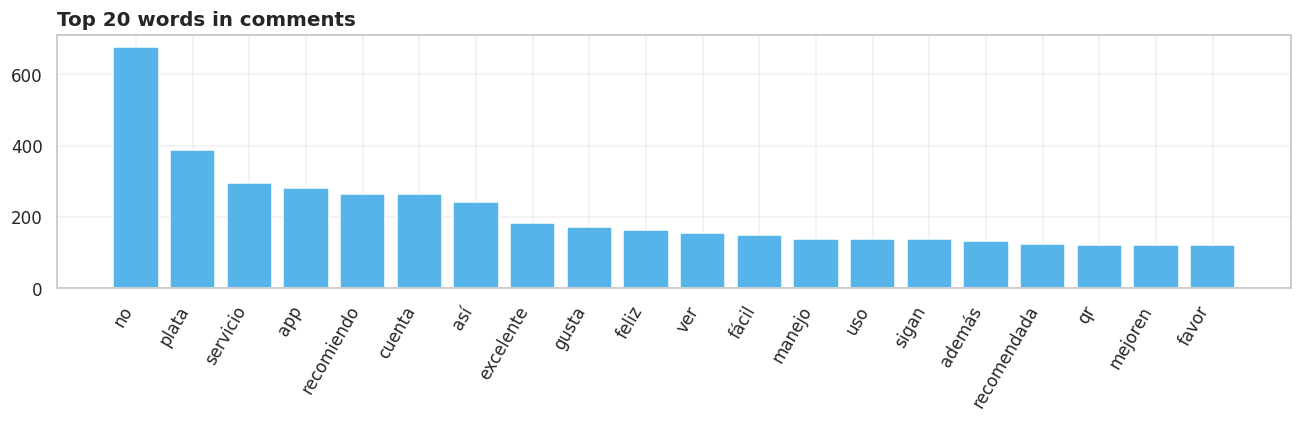

In [88]:
words, freqs = zip (*nltk.FreqDist(all_tokens).most_common(20))
fig, ax = plt.subplots(figsize = (12 , 4))
ax.bar(words, freqs, color = "#56B4E9")
plt.xticks(rotation=60, ha="right")
ax.set_title("Top 20 words in comments")
fig.tight_layout()
save_fig(fig, "top_20_words_in_comments", module = 5)
plt.show()

## 5.3 - Word Cloud

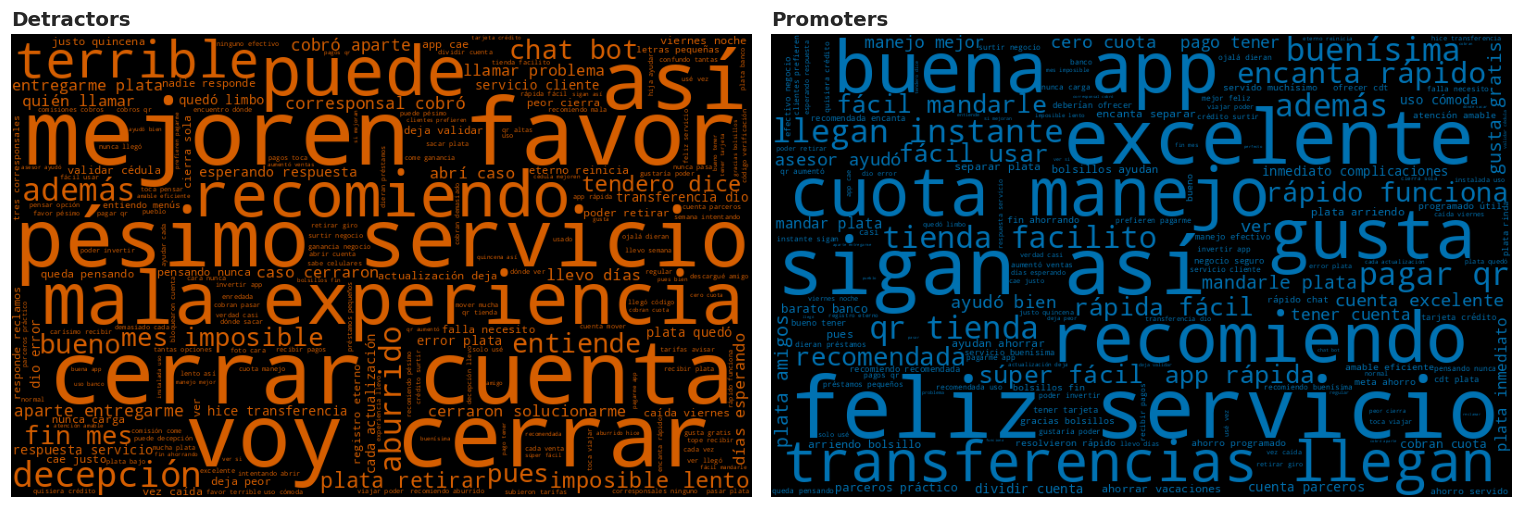

In [89]:
fig, axes = plt.subplots(1, 2, figsize = (14, 5))
for ax, group, color in zip(axes, ["Detractor", "Promoter"], [SENTIMENT_COLORS["Negativo"], SENTIMENT_COLORS["Positivo"]]):
  text = " ".join(" ".join(t) for t in df.loc[df["nps_group"] == group, "tokens"])
  wc = WordCloud (width = 800, height = 500, background_color = "black", color_func = lambda * args,
                  c = color, **kwargs : c, # One readable color
                  random_state = SEED).generate(text)
  ax.imshow(wc)
  ax.axis("off")
  ax.set_title(f"{group}s")

fig.tight_layout()
save_fig(fig, "wordclouds_nps", module = 5)
plt.show()

## 5.4 - **Findings - Text**
- 1. **Only 253 distinct words** in 1,990 comments: customers write short, repetitive (templated) phrases.
- 2. **Detractors** talk about closing the account, cash withdrawals (corresponsal, tendero), chat bot and app errors.
- 3. **Promoters** value instant transfers, QR payments, zero fees and savings pockets.
- 4. **Limitation:** "recomiendo" appears in detractors because the word cloud drops "no" ("no la recomiendo"). Word counts lose context → sentiment analysis (Module 6) is needed.

# 6 - Textblob

### **Translation note**
TextBlob only understands English: Spanish text returns polarity 0.

**Adjustment implemented:** comments are translated ES -> EN with the open model `Helsinki-NLP/opus-mt-es-en` (MarianMT) before applying TextBlob.
Only unique comments are translated, and results are cached in `outputs/06_translations.csv` so re-runs are instant.

## 6.2 - Translation

In [90]:
def remove_emojis(text):
    """Drop emojis and pictograms (same as the reference notebook)."""
    emoji_pattern = re.compile("["
        "\U0001F600-\U0001F64F" "\U0001F300-\U0001F5FF" "\U0001F680-\U0001F6FF"
        "\U0001F1E0-\U0001F1FF" "\U00002702-\U000027B0" "\U000024C2-\U0001F251"
        "]+", flags=re.UNICODE)
    return emoji_pattern.sub("", text).strip()

# Colombian terms the translator gets wrong -> neutral Spanish
GLOSSARY = {"corresponsales": "puntos de retiro", "corresponsal": "punto de retiro",
            "nunca carga": "nunca termina de cargar", "plata": "dinero",
            "parceros": "amigos", "facilito": "muy fácil"}

def split_clauses(text):
    """Split a comment into short clauses and apply the glossary."""
    clauses = []
    for c in re.split(r"[.,!?]", text):
        c = c.strip().capitalize()
        for es, better in GLOSSARY.items():
            c = c.replace(es, better)
        if c:
            clauses.append(c)
    return clauses

df["comment_es"] = df["comentario"].fillna("").apply(remove_emojis)
df["clauses_es"] = df["comment_es"].apply(split_clauses)
unique_clauses = sorted({c for clauses in df["clauses_es"] for c in clauses})
print("Unique clauses to translate:", len(unique_clauses))

Unique clauses to translate: 371


In [91]:
MT_NAME = "Helsinki-NLP/opus-mt-es-en"
TRANSLATION_CACHE = OUT_DIR / "06_translations.xlsx"

if TRANSLATION_CACHE.exists():
    translations = pd.read_excel(TRANSLATION_CACHE)
else:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    mt_tokenizer = MarianTokenizer.from_pretrained(MT_NAME)
    mt_model = MarianMTModel.from_pretrained(MT_NAME).to(device)
    translated = []
    for i in range(0, len(unique_clauses), 32):
        batch = mt_tokenizer(unique_clauses[i:i + 32], return_tensors="pt",
                             padding=True, truncation=True).to(device)
        with torch.no_grad():
            output = mt_model.generate(**batch, num_beams=1, max_new_tokens=64)
        translated += mt_tokenizer.batch_decode(output, skip_special_tokens=True)
    translations = pd.DataFrame({"clause_es": unique_clauses, "clause_en": translated})
    translations.to_excel(TRANSLATION_CACHE, index=False)

# Rebuild each comment from its translated clauses
clause_map = dict(zip(translations["clause_es"], translations["clause_en"]))
df["comment_en"] = df["clauses_es"].apply(lambda cl: " ".join(clause_map[c] for c in cl))
df[["comment_es", "comment_en"]].head(5)

,comment_es,comment_en
0,"Bueno, se queda pensando y nunca carga, pero pagar con QR en la tienda es facilito",Okay. He's thinking and never ends loading. But paying with qr in the store is very easy
1,Gracias a los bolsillos por fin estoy ahorrando,Thanks to the pockets I'm finally saving
2,La descargué por un amigo pero no la he usado,I downloaded it for a friend but I haven't used it.
3,Fui a tres corresponsales y ninguno tenía efectivo. Voy a cerrar la cuenta,I went to three withdrawal points and none had cash. I'm gonna close the account.
4,No encuentro dónde ver lo que me llegó. No la recomiendo,I can't find where to see what got me. I don't recommend it.


## 6.3 - Polarity

In [92]:
def get_polarity(text):
    """TextBlob polarity: -1 (negative) to +1 (positive)"""
    return TextBlob(text).sentiment.polarity

def x_range(x):
    """Classify polarity into 3 classes"""
    if x > 0:
      return "Positivo"
    elif x == 0:
      return "Neutro"
    return "Negativo"

df["polarity"] = df["comment_en"].apply(get_polarity)
df["sentiment"] = df["polarity"].apply(x_range)

nlp = df[df["flag_no_comment"] == 0] # Only customers with a comment
sent_share = nlp["sentiment"].value_counts().reindex(list(SENTIMENT_COLORS), fill_value = 0)
print (sent_share)

sentiment
Negativo     456
Neutro       288
Positivo    1246
Name: count, dtype: int64


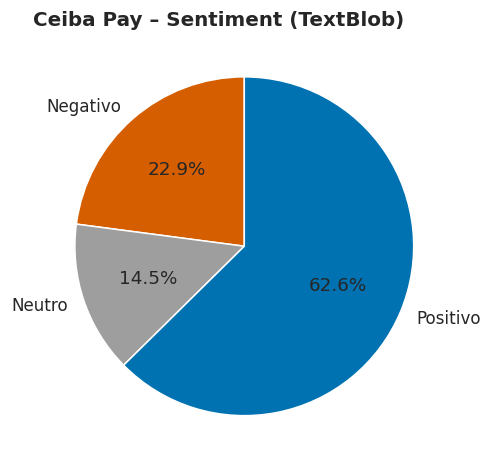

In [93]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(sent_share, labels=sent_share.index, colors=list(SENTIMENT_COLORS.values()),
       autopct="%1.1f%%", startangle=90)
ax.set_title("Ceiba Pay – Sentiment (TextBlob)")
save_fig(fig, "sentiment_pie", module=6)
plt.show()

## 6.4 - NPS Benchmark

In [94]:
# NPS is used only to check TextBlob, never as an input
check = (pd.crosstab(nlp["nps_group"], nlp["sentiment"], normalize = "index").reindex(columns = list(SENTIMENT_COLORS), fill_value = 0) * 100)
rho, p = stats.spearmanr(nlp["polarity"], nlp["nps_0_10"])
print(f"Spearman polarity VS NPS: rho= {rho:.2f}, p={p:.2g}")

Spearman polarity VS NPS: rho= 0.53, p=3.3e-143


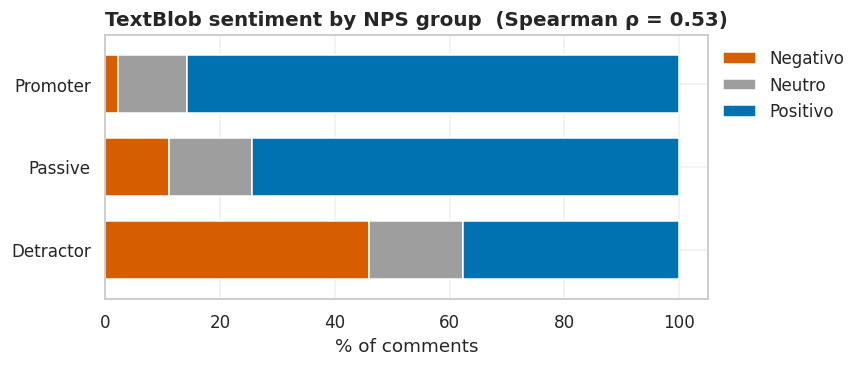

sentiment,Negativo,Neutro,Positivo
nps_group,,,
Detractor,45.9,16.4,37.7
Passive,11.0,14.5,74.5
Promoter,2.1,12.2,85.7


In [95]:
fig, ax = plt.subplots(figsize=(8, 3.5))
check.plot(kind="barh", stacked=True, color=list(SENTIMENT_COLORS.values()), ax=ax, width=0.7)
ax.set_title(f"TextBlob sentiment by NPS group  (Spearman ρ = {rho:.2f})")
ax.set_xlabel("% of comments")
ax.set_ylabel("")
ax.legend(frameon=False, bbox_to_anchor=(1, 1))
fig.tight_layout()
save_fig(fig, "sentiment_vs_nps", module=6)
plt.show()

check.round(1)

## 6.5 - Topics

In [96]:
# Rule-based topics: comments follow templates, so keywords capture the reason reliably
TOPICS = {
    "Cash withdrawal":      ["corresponsal", "tendero", "retirar", "sacar la plata", "tenía efectivo"],
    "App failures":         ["se cae", "caída", "falla", "error", "limbo", "lento", "se cierra",
                             "nunca carga", "actualización", "imposible"],
    "Customer service":     ["chat", "reclamos", "servicio al cliente", "quién llamar", "caso",
                             "asesor", "atención"],
    "Sign-up & validation": ["registro", "cédula", "código de verificación", "foto de la cara",
                             "abrir la cuenta"],
    "Hard to use":          ["letras", "menús", "enredada", "confundo", "hija", "no encuentro"],
    "Fees & limits":        ["comisi", "tarifas", "cobran demasiado", "carísimo", "pasar la plata al banco",
                             "bloque", "congelaron", "tope", "límite"],
    "Free / no fees":       ["gratis", "cuota de manejo", "no pago nada", "barato"],
    "Ease & speed":         ["fácil de usar", "rápido que funciona", "cómoda", "funciona perfecto", "para todo"],
    "P2P transfers":        ["transferencia", "mandar plata", "mandarle plata", "dividir la cuenta"],
    "QR & business":        ["pagar con qr", "pagos por qr", "pagarme", "efectivo en el negocio"],
    "Savings":              ["bolsillo", "ahorr"],
    "New products":         ["crédito", "préstamos", "invertir", "cdt"],
    "Low usage":            ["no la he usado", "casi no la uso", "una vez", "instalada", "descargué",
                             "uso más el banco"],
}

TOPIC_COLS = list(TOPICS)
for topic, keywords in TOPICS.items():
    df[topic] = df["comment_clean"].str.contains("|".join(keywords)).astype(int)

nlp = df[df["flag_no_comment"] == 0]
print("Comments with at least one topic:", f"{(nlp[TOPIC_COLS].sum(axis=1) > 0).mean():.1%}")

Comments with at least one topic: 99.6%


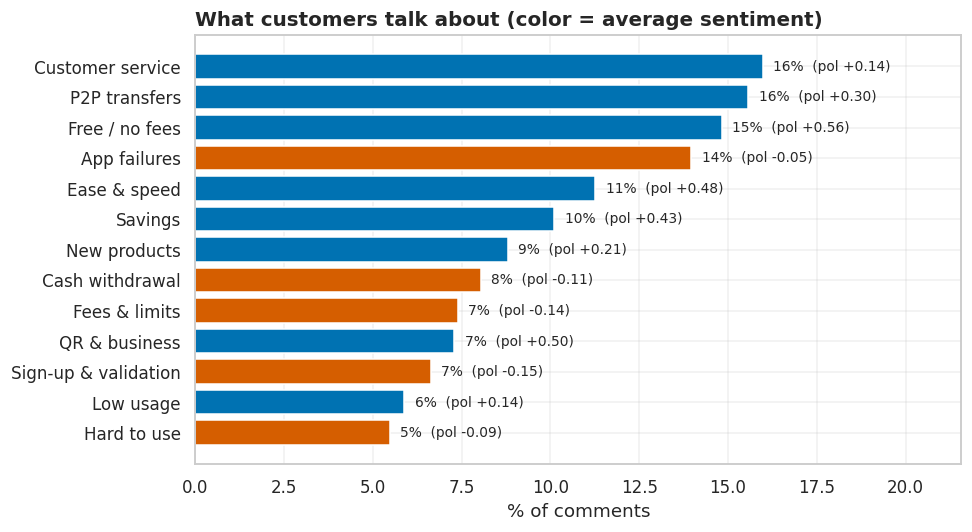

,mentions_pct,avg_polarity
Hard to use,5.48,-0.09
Low usage,5.88,0.14
Sign-up & validation,6.63,-0.15
QR & business,7.29,0.50
Fees & limits,7.39,-0.14
Cash withdrawal,8.04,-0.11
New products,8.79,0.21
Savings,10.10,0.43
Ease & speed,11.26,0.48
App failures,13.97,-0.05


In [97]:
topic_summary = pd.DataFrame({
    "mentions_pct": nlp[TOPIC_COLS].mean() * 100,
    "avg_polarity": [nlp.loc[nlp[t] == 1, "polarity"].mean() for t in TOPIC_COLS],
}, index=TOPIC_COLS).sort_values("mentions_pct")

fig, ax = plt.subplots(figsize=(9, 5))
colors = [SENTIMENT_COLORS["Negativo"] if p < 0 else SENTIMENT_COLORS["Positivo"]
          for p in topic_summary["avg_polarity"]]
ax.barh(topic_summary.index, topic_summary["mentions_pct"], color=colors)
for i, (m, p) in enumerate(zip(topic_summary["mentions_pct"], topic_summary["avg_polarity"])):
    ax.text(m + 0.3, i, f"{m:.0f}%  (pol {p:+.2f})", va="center", fontsize=9)
ax.set_title("What customers talk about (color = average sentiment)")
ax.set_xlabel("% of comments")
ax.set_xlim(0, topic_summary["mentions_pct"].max() * 1.35)
fig.tight_layout()
save_fig(fig, "topics", module=6)
plt.show()

topic_summary.round(2)

## 6.6 - **Findings – Sentiment & topics**
- 1. **TextBlob is reasonably valid for this data**: polarity correlates with NPS (Spearman ρ = 0.53). 85.7% of promoters' comments are positive vs 37.7% of detractors'.
- 2. **TextBlob is more optimistic than NPS** (62.6% positive vs 35% promoters). It misses complaints without emotional words ("I'm gonna close the account", "never ends loading"), mixed comments ("okay… but…") and sarcasm.
- 3. **Passives are the "satisfied but silent" group**: 74.5% positive comments, yet they don't recommend → conversion opportunity.
- 4. **Pain points (fix)**: sign-up & validation (−0.15), fees & limits (−0.14), cash withdrawal (−0.11), hard to use (−0.09). App failures is the most mentioned complaint (14%) but scores only −0.05, because technical descriptions carry no emotional words.
- 5. **Strengths (protect)**: no fees (+0.56), QR for business (+0.50), ease & speed (+0.48), savings pockets (+0.43), P2P transfers (+0.30).
- 6. **Customer service** is the most mentioned topic (16%) with mixed tone (+0.14): helpful advisors vs. a bot that doesn't understand.
- 7. **Growth signal**: 9% ask for credit, loans or investment products (+0.21, requests from satisfied customers).

**Methodology note**: comments were translated clause by clause with a glossary of Colombian terms. A first full-sentence translation dropped final sentences ("Voy a cerrar la cuenta"). The corrected version was kept even though its NPS correlation is slightly lower (0.53 vs 0.57): the reference label is used to validate, never to choose.

**Limitations**: TextBlob is lexicon-based and does not detect sarcasm or factual complaints; machine translation may still be literal in places.

# 7 - K-Means

In [98]:
# Choose variables, apply `log` and standardizes
# Usage-only variables (brief: no age, strata or city; no sentiment)
LOG_COLS = ["transacciones_mes", "ticket_promedio_cop", "saldo_promedio_cop"]
CLUSTER_COLS = ["antiguedad_meses"] + LOG_COLS + PCT_COLS + ["usa_bolsillo_ahorro"]

X = df[CLUSTER_COLS].copy()
X[LOG_COLS] = np.log1p(X[LOG_COLS])          # fix skewness (brief recommendation)
X_scaled = StandardScaler().fit_transform(X)  # pesos and % on the same scale
print("Features:", X.shape[1], "| Customers:", X.shape[0])

Features: 9 | Customers: 2000


**Variables excluded from clustering**
- `edad`, `estrato`, `ciudad`: used only to describe segments (brief requirement).
- `margen_mensual_cop`, `nps_0_10`, sentiment, topics: outcomes, used to profile, never to build segments.
- `dias_desde_ultima_tx`: redundant with transactions (ρ = −0.85, Module 4).
- `contactos_soporte_6m`: a friction signal, not a usage behavior.

## 7.2 - Choose K

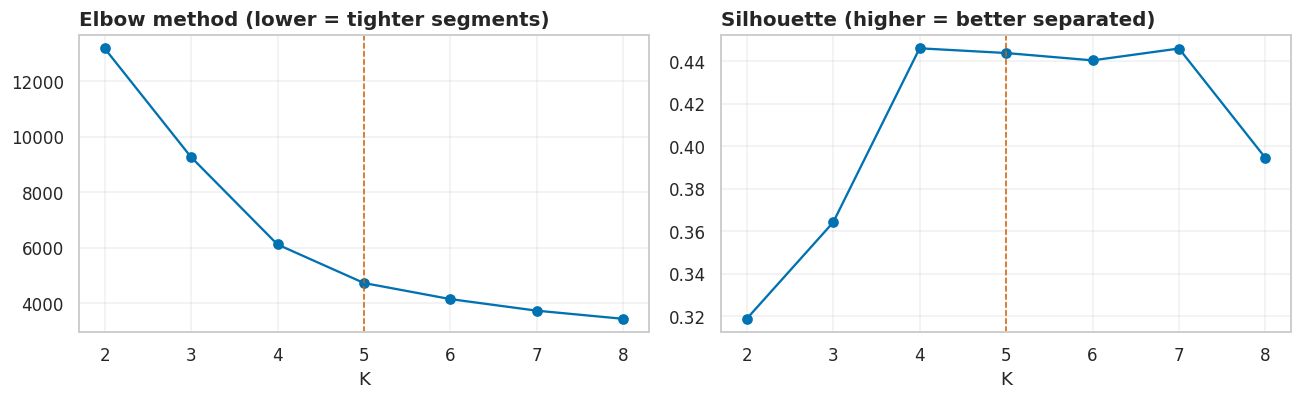

,k,inertia,silhouette,smallest_segment
0,2,13189.448,0.319,411
1,3,9267.384,0.364,401
2,4,6114.910,0.446,300
3,5,4725.557,0.444,300
4,6,4145.417,0.440,148
5,7,3728.006,0.446,115
6,8,3433.944,0.394,115


In [99]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X_scaled, km.labels_),
                 "smallest_segment": np.bincount(km.labels_).min()})
k_scores = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(k_scores["k"], k_scores["inertia"], marker="o", color="#0072B2")
axes[0].set_title("Elbow method (lower = tighter segments)")
axes[1].plot(k_scores["k"], k_scores["silhouette"], marker="o", color="#0072B2")
axes[1].set_title("Silhouette (higher = better separated)")
for ax in axes:
    ax.set_xlabel("K")
    ax.axvline(5, color="#D55E00", linestyle="--", linewidth=1)
fig.tight_layout()
save_fig(fig, "choose_k", module=7)
plt.show()

k_scores.round(3)

## 7.3 - Train Model

In [100]:
K_FINAL = 5
kmeans_pipe = Pipeline([("scaler", StandardScaler()),
                        ("kmeans", KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED))])
df["cluster"] = kmeans_pipe.fit_predict(X)

# Name segments by their profile, not by cluster number (numbers can change between runs)
means = df.groupby("cluster")[CLUSTER_COLS].mean()
SEGMENT_NAMES = {                                             # Categories to identify customers in a innovative way
    means["pct_pagos_qr"].idxmax(): "QR merchants",
    means["pct_retiros_corresponsal"].idxmax(): "Cash-out users",
    means["usa_bolsillo_ahorro"].idxmax(): "Savers",
    means["transacciones_mes"].idxmin(): "Dormant",
    means["pct_transferencias_p2p"].idxmax(): "P2P youth",
}
assert len(SEGMENT_NAMES) == K_FINAL, "Two rules picked the same cluster: review names"
df["segment"] = df["cluster"].map(SEGMENT_NAMES)

SEGMENT_ORDER = ["QR merchants", "Savers", "P2P youth", "Cash-out users", "Dormant"]
SEGMENT_COLORS = dict(zip(SEGMENT_ORDER, SEGMENT_PALETTE))
df["segment"].value_counts().reindex(SEGMENT_ORDER)

,count
segment,
QR merchants,300
Savers,399
P2P youth,601
Cash-out users,400
Dormant,300


## 7.4 - Profile

segment,QR merchants,Savers,P2P youth,Cash-out users,Dormant
antiguedad_meses,23.5,19.0,17.0,29.0,6.0
transacciones_mes,184.0,23.0,34.0,4.0,1.0
ticket_promedio_cop,17050.0,119300.0,26000.0,288350.0,30900.0
saldo_promedio_cop,1692150.0,862300.0,79100.0,147500.0,10100.0
pct_pagos_qr,71.4,19.2,14.2,0.7,9.9
pct_transferencias_p2p,9.1,30.6,64.8,8.1,48.2
pct_retiros_corresponsal,13.9,1.5,3.5,81.2,22.4
pct_pago_servicios,3.2,44.6,14.5,6.5,11.0
usa_bolsillo_ahorro,0.0,1.0,0.0,0.0,0.0
margen_mensual_cop,35215.0,12140.0,2520.0,4885.0,170.0


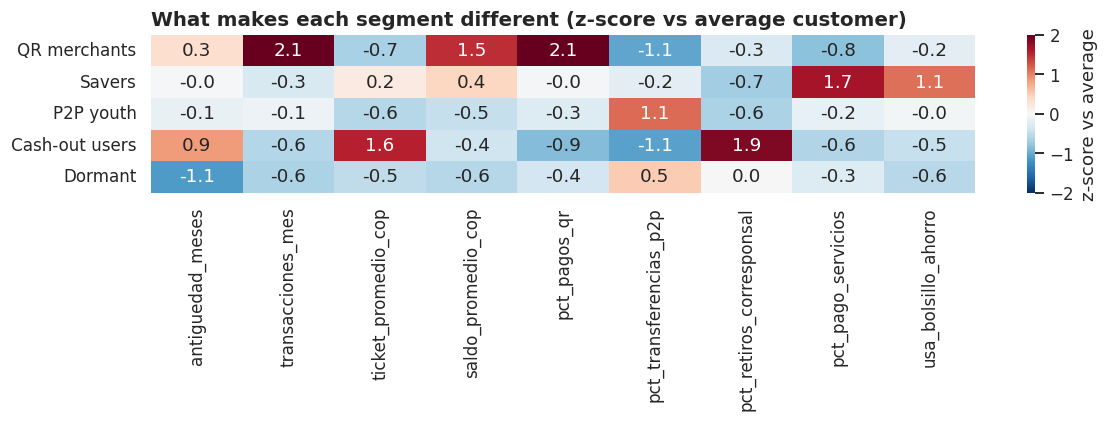

In [101]:
# Business-unit table (medians are robust to skew)
PROFILE_COLS = CLUSTER_COLS + ["margen_mensual_cop", "nps_0_10"]
profile = df.groupby("segment")[PROFILE_COLS].median().reindex(SEGMENT_ORDER)
profile["customers"] = df["segment"].value_counts()
profile["margin_share_%"] = (df.groupby("segment")["margen_mensual_cop"].sum()
                             / df["margen_mensual_cop"].sum() * 100)
display(profile.round(1).T)

# Heatmap: how each segment differs from the average customer
z = ((df.groupby("segment")[CLUSTER_COLS].mean() - df[CLUSTER_COLS].mean())
     / df[CLUSTER_COLS].std()).reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(z, cmap=DIV_CMAP, center=0, vmin=-2, vmax=2, annot=True, fmt=".1f",
            ax=ax, cbar_kws={"label": "z-score vs average"})
ax.set_title("What makes each segment different (z-score vs average customer)")
ax.set_ylabel("")
ax.grid(False)
fig.tight_layout()
save_fig(fig, "segment_heatmap", module=7)
plt.show()

## 7.5 - 2D Visualization

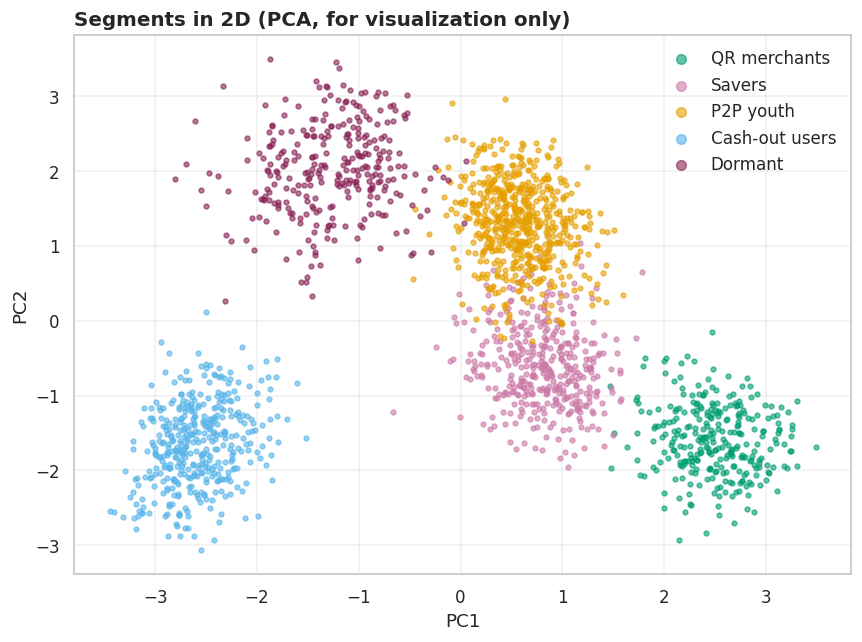

In [102]:
coords = PCA(n_components=2, random_state=SEED).fit_transform(kmeans_pipe["scaler"].transform(X))

fig, ax = plt.subplots(figsize=(8, 6))
for seg in SEGMENT_ORDER:
    m = df["segment"] == seg
    ax.scatter(coords[m, 0], coords[m, 1], s=10, alpha=0.6, color=SEGMENT_COLORS[seg], label=seg)
ax.set_title("Segments in 2D (PCA, for visualization only)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(frameon=False, markerscale=2)
fig.tight_layout()
save_fig(fig, "segments_pca", module=7)
plt.show()

## 7.6 - Features / Characteristics

In [103]:
charac = pd.DataFrame({
    "median_age": df.groupby("segment")["edad"].median(),
    "median_strata": df.groupby("segment")["estrato"].median(),
    "top_city": df.groupby("segment")["ciudad"].agg(lambda s: s.value_counts().index[0]),
    "small_towns_%": df.groupby("segment")["ciudad"].apply(
        lambda s: (s == "Municipio intermedio").mean() * 100),
}).reindex(SEGMENT_ORDER)
charac.round(1)

,median_age,median_strata,top_city,small_towns_%
segment,,,,
QR merchants,39.0,2.0,Bogotá,17.0
Savers,33.0,4.0,Bogotá,18.5
P2P youth,21.0,2.0,Bogotá,17.8
Cash-out users,55.0,2.0,Municipio intermedio,39.0
Dormant,34.0,2.0,Bogotá,16.7


## 7.7 - Save Model

In [104]:
joblib.dump({"pipeline": kmeans_pipe, "features": CLUSTER_COLS, "log_cols": LOG_COLS,
             "segment_names": SEGMENT_NAMES}, MODEL_DIR / "kmeans_segments.joblib")

saved = joblib.load(MODEL_DIR / "kmeans_segments.joblib")
print("Reloaded model reproduces labels:", (saved["pipeline"].predict(X) == df["cluster"]).all())

Reloaded model reproduces labels: True


## 7.8 - **Findings – Segmentation (K-Means, K = 5)**
- 1. **Clear structure**: silhouette 0.44 and well-separated groups in PCA. K = 5 chosen over K = 4 (same silhouette) because it isolates dormant customers.

- 2. **QR merchants** (15% of customers) generate **54% of margin**: 184 tx/month, $1.7M balance, 71% QR payments. Their NPS median is only 5 → the most valuable segment is unhappy.

- 3. **Savers** (20%): bill payments + savings pockets, strata 4, NPS 9 and 27% of margin → the happiest, second most profitable.

- 4. **P2P youth** (30%): age 21, 65% person-to-person transfers, NPS 8 but only 9% of margin → loyal but low value.

- 5. **Cash-out users** (20%): age 55, 81% cash withdrawals, 39% in small towns, NPS 5 → the wallet as a cash bridge, hurt by agent network problems.

- 6. **Dormant** (15%): 6 months tenure, 1 tx/month, $10k balance, 0.3% of margin → failed activation.

# 8 - Priority Map

In [105]:
# Value VS Segment Satisfaction
def nps_score(groups):
    """NPS = % promoters - % detractors."""
    return ((groups == "Promoter").mean() - (groups == "Detractor").mean()) * 100

nlp = df[df["flag_no_comment"] == 0]
seg_kpi = pd.DataFrame({
    "customers": df["segment"].value_counts(),
    "nps": df.groupby("segment")["nps_group"].apply(nps_score),
    "positive_comments_%": nlp.groupby("segment")["sentiment"].apply(lambda s: (s == "Positivo").mean() * 100),
    "avg_polarity": nlp.groupby("segment")["polarity"].mean(),
    "margin_share_%": df.groupby("segment")["margen_mensual_cop"].sum() / df["margen_mensual_cop"].sum() * 100,
}).reindex(SEGMENT_ORDER)

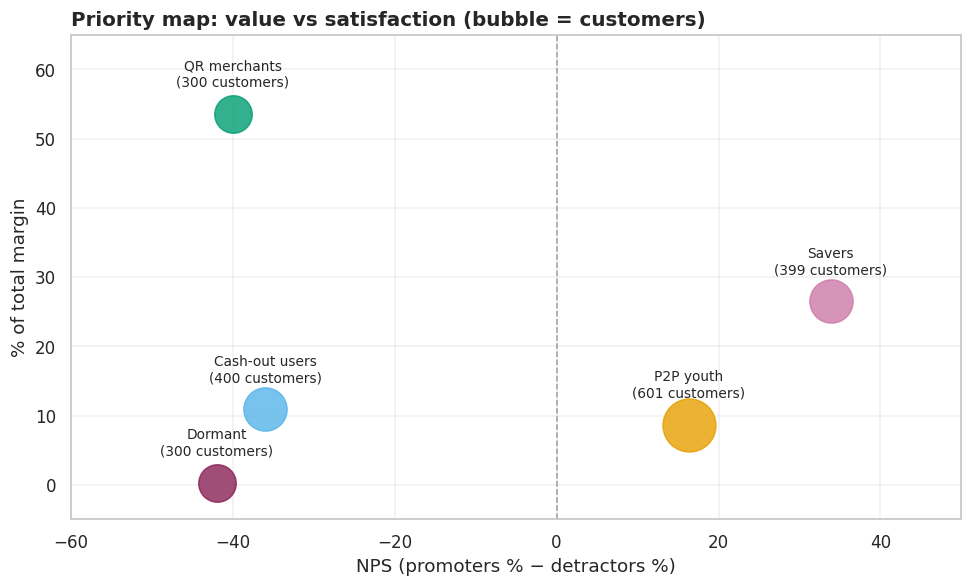

,customers,nps,positive_comments_%,avg_polarity,margin_share_%
segment,,,,,
QR merchants,300,-40.0,47.2,0.0,53.6
Savers,399,33.8,75.3,0.3,26.5
P2P youth,601,16.3,74.7,0.3,8.7
Cash-out users,400,-36.0,54.0,0.1,10.9
Dormant,300,-42.0,48.5,0.0,0.3


In [106]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for seg, r in seg_kpi.iterrows():
    ax.scatter(r["nps"], r["margin_share_%"], s=r["customers"] * 2, color=SEGMENT_COLORS[seg], alpha=0.8)
    ax.annotate(f"{seg}\n({r['customers']:.0f} customers)", (r["nps"], r["margin_share_%"]),
                textcoords="offset points", xytext=(0, 18), ha="center", fontsize=9)
ax.axvline(0, color="#9E9E9E", linestyle="--", linewidth=1)
ax.set_xlabel("NPS (promoters % − detractors %)")
ax.set_ylabel("% of total margin")
ax.set_title("Priority map: value vs satisfaction (bubble = customers)")
ax.set_xlim(-60, 50)
ax.set_ylim(-5, 65)
fig.tight_layout()
save_fig(fig, "priority_map", module=8)
plt.show()

seg_kpi.round(1)

## 8.2 - Topics by Segment

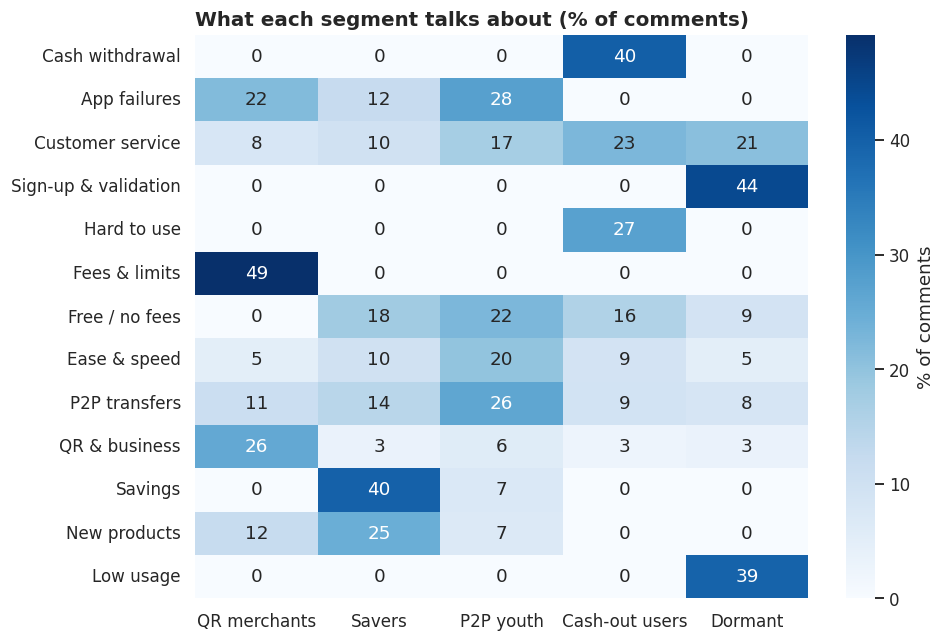

In [107]:
topic_by_seg = (nlp.groupby("segment")[TOPIC_COLS].mean() * 100).reindex(SEGMENT_ORDER).T

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(topic_by_seg, cmap=SEQ_CMAP, vmin=0, annot=True, fmt=".0f", ax=ax,
            cbar_kws={"label": "% of comments"})
ax.set_title("What each segment talks about (% of comments)")
ax.set_xlabel("")
ax.grid(False)
fig.tight_layout()
save_fig(fig, "topics_by_segment", module=8)
plt.show()

## 8.3 - **2027 budget recommendations**

| # | Finding | Segment | Concrete action | Tracking KPI |
|---|---|---|---|---|
| 1 | Most valuable segment is unhappy: 54% of margin, NPS −40; 49% of comments about fees & limits, 22% about app failures; 2.4 support contacts per customer | **QR merchants** (300, 15%) | **Merchant plan**: volume-tiered QR fees, higher limits for verified businesses, priority support line and stability on paydays | Segment NPS (−40 -> 0); monthly merchant churn; segment margin |
| 2 | Cash access drives dissatisfaction: NPS −36; 40% of comments about withdrawals (no cash, extra charges, travel); age 55, 39% in small towns; 27% find the app hard to use | **Cash-out users** (400, 20%) | **Card-less QR withdrawals at retail chains with small-town reach** (D1, Ara, Dollarcity), following the Nu–D1 precedent (Sep 2026, ~2,800 stores, 540 municipalities); add a "simple mode" (large text, fewer menus) | Segment NPS (−36 -> −10); % comments about cash withdrawal; successful withdrawals / attempts |
| 3 | Happiest segment asks for more: NPS +34, 27% of margin; 25% of comments request CDT, investment or credit | **Savers** (399, 20%) | **Launch a yield-bearing savings pocket / digital CDT** for existing savers | Product adoption %; average balance; segment margin |

**Next priority (low cost)**: Dormant customers (15%) are stuck at sign-up: 44% mention ID validation issues. Fixing onboarding could activate them.

# **Main Findings**

- Each segment has a different problem. That’s why a one-size-fits-all approach wouldn’t work, and a recommendation is needed for each segment.

- Such perfect zeros (for example, “Cash withdrawal” appears only among Cash-out users) indicate that the data is synthetic. This should be noted in the limitations.

# 9 - Export Results

In [108]:
FINAL_COLS = ["id_cliente", "segment", "nps_0_10", "nps_group", "comentario", "comment_en",
              "polarity", "sentiment"] + TOPIC_COLS

with pd.ExcelWriter(OUT_DIR / "09_ceiba_pay_results.xlsx") as writer:
    df[FINAL_COLS].to_excel(writer, sheet_name="customers", index=False)
    seg_kpi.round(1).to_excel(writer, sheet_name="segment_kpis")
    profile.round(1).to_excel(writer, sheet_name="segment_profile")
    topic_by_seg.round(1).to_excel(writer, sheet_name="topics_by_segment")

print("Saved:", OUT_DIR / "09_ceiba_pay_results.xlsx")
print("Figures saved:", len(list(FIG_DIR.glob("*.png"))))

Saved: /content/drive/MyDrive/Colab Notebooks/No supervisado/Workshops/Workshop 5 - Ceiba Pay Clients/outputs/09_ceiba_pay_results.xlsx
Figures saved: 17


## 9.2 - Integrity Check (MD5 Hash)

In [109]:
md5_end = file_md5(DATA_FILE)
print("MD5 start:", MD5_ORIGINAL)
print("MD5 end  :", md5_end)
assert md5_end == MD5_ORIGINAL, "Original file was modified!"
print("Original file intact")

MD5 start: 3fcea7708df095a7677b249cdc8723b9
MD5 end  : 3fcea7708df095a7677b249cdc8723b9
Original file intact


## 9.3 - **Executive summary**

**Business question:** What customer segments does Ceiba Pay have, how does each feel about the service, and where should the 2027 budget go to protect margin and grow?

**Data quality:** 2,000 customers, no duplicates. Channel shares were stored in per-mille with 736 cells as fractions (fixed with a verifiable rule); 15 missing ages imputed; 45 impossible inactivity values capped. No customer was removed. Original file verified intact (MD5).

**How customers feel:** NPS = −8 (43% detractors, 35% promoters). TextBlob sentiment (after ES→EN translation) agrees with NPS (ρ = 0.53) but is more optimistic: it misses factual complaints and sarcasm.

**Segments (K-Means, K = 5, usage variables only, silhouette 0.44):**

| Segment | Customers | NPS | % margin | Main topic |
|---|---|---|---|---|
| QR merchants | 15% | −40 | 54% | Fees & limits (49%) |
| Savers | 20% | +34 | 27% | Savings (40%), new products (25%) |
| P2P youth | 30% | +16 | 9% | P2P transfers, app failures |
| Cash-out users | 20% | −36 | 11% | Cash withdrawal (40%), hard to use |
| Dormant | 15% | −42 | 0.3% | Sign-up & validation (44%) |

**Key insight:** each behavior group feels differently and complains about something different. The most valuable segment (QR merchants) is among the unhappiest.

**Recommendations 2027:** see 8.3 (merchant plan, retail cash-out alliances, savings products).

**Limitations:** the data looks synthetic (topics appear in only one segment, very clean clusters); TextBlob is lexicon-based and relies on machine translation; topics come from keyword rules built for these templates; NPS is a single survey snapshot.